In [8]:
import pandas as pd 
df = pd.read_csv("../data/listings.csv")
print(df.shape)
print(df.dtypes)
print(df.columns.tolist())

(15584, 79)
id                                                int64
listing_url                                      object
scrape_id                                         int64
last_scraped                                     object
source                                           object
                                                 ...   
calculated_host_listings_count                    int64
calculated_host_listings_count_entire_homes       int64
calculated_host_listings_count_private_rooms      int64
calculated_host_listings_count_shared_rooms       int64
reviews_per_month                               float64
Length: 79, dtype: object
['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview', 'picture_url', 'host_id', 'host_url', 'host_name', 'host_since', 'host_location', 'host_about', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url', 'host_picture_url', 'host_neig

In [9]:
# Check target var
print(df['price'].dtype)
print(df['price'].head(22))

# Count Null
nulls = df.isnull().sum()
print(nulls[nulls > 0 ].sort_values(ascending=False))

# Distribution of room types
print(df['room_type'].value_counts())

# Quick price stats
print(df['price'].describe)

object
0         NaN
1      $45.00
2     $160.00
3      $50.00
4         NaN
5      $70.00
6      $57.00
7         NaN
8     $400.00
9      $54.00
10     $85.00
11     $83.00
12    $213.00
13     $84.00
14    $150.00
15     $41.00
16    $120.00
17     $74.00
18    $126.00
19     $77.00
20        NaN
21    $936.00
Name: price, dtype: object
calendar_updated                15584
neighbourhood_group_cleansed    15584
host_neighbourhood               9836
neighborhood_overview            8075
neighbourhood                    8075
host_about                       7695
host_location                    5178
first_review                     2343
last_review                      2343
review_scores_rating             2343
review_scores_accuracy           2343
review_scores_cleanliness        2343
reviews_per_month                2343
review_scores_checkin            2343
review_scores_communication      2343
review_scores_location           2343
review_scores_value              2343
host_respons

In [10]:
# Drop 100% null columns and usuless ones
cols_to_drop = [
    'calendar_updated', 'neighbourhood_group_cleansed',
    'listing_url', 'scrape_id', 'picture_url', 'host_url',
    'host_thumbnail_url', 'host_picture_url', 'last_scraped',
    'calendar_last_scraped', 'source'
]
df.drop(columns=cols_to_drop, inplace=True)


In [11]:
df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)
df.dropna(subset = ['price'], inplace=True)

In [12]:
print(df['price'].dtype, df['price'].describe(), f"Rows remaining: {len(df)}",sep='\n')

float64
count    14524.000000
mean       122.899821
std        452.296317
min          9.000000
25%         54.000000
50%         78.000000
75%        119.000000
max      38000.000000
Name: price, dtype: float64
Rows remaining: 14524


Listings above €500:' 280
Listings above €1000: 50
99th percentile cutoff: $601.5400000000009
Rows after removing outliers: 14378


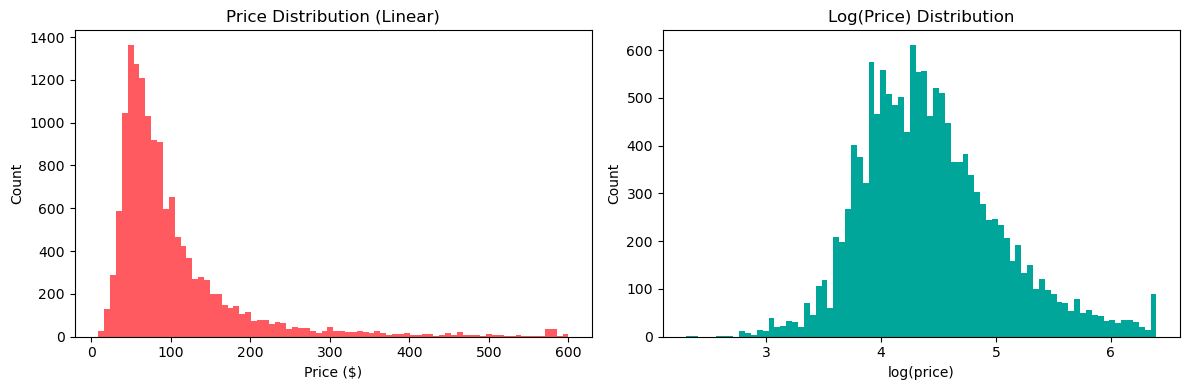

Clean file saved ✅


In [13]:
import matplotlib.pyplot as plt
import numpy as np

# listing > 500€
print(f"Listings above €500:' {(df['price'] > 500).sum()}")
print(f"Listings above €1000: {(df['price'] > 1000).sum()}")

upper = df['price'].quantile(0.99)
print(f"99th percentile cutoff: ${upper}")
df = df[df['price'] <= upper]
print(f"Rows after removing outliers: {len(df)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['price'], bins=80, color='#FF5A5F', edgecolor='none')
axes[0].set_title('Price Distribution (Linear)')
axes[0].set_xlabel('Price ($)')
axes[0].set_ylabel('Count')

axes[1].hist(np.log1p(df['price']), bins=80, color='#00A699', edgecolor='none')
axes[1].set_title('Log(Price) Distribution')
axes[1].set_xlabel('log(price)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

df.to_csv('../data/processed/listings_clean.csv', index=False)
print("Clean file saved ✅")

In [14]:
df = pd.read_csv('../data/processed/listings_clean.csv')

cols_to_keep = [
    'price', 'room_type', 'accommodates', 'bathrooms', 'bedrooms',
    'beds', 'amenities', 'neighbourhood_cleansed', 'latitude', 'longitude',
    'host_is_superhost', 'host_response_rate', 'host_acceptance_rate',
    'host_identity_verified', 'calculated_host_listings_count',
    'review_scores_rating', 'review_scores_cleanliness',
    'review_scores_location', 'review_scores_value',
    'number_of_reviews', 'reviews_per_month',
    'availability_365', 'minimum_nights', 'instant_bookable'
]
df = df[cols_to_keep]

# Median fill — property features
for col in ['bathrooms', 'bedrooms', 'beds']:
    df[col].fillna(df[col].median(), inplace=True)

# Boolean fill
for col in ['host_is_superhost', 'host_identity_verified']:
    df[col].fillna(False, inplace=True)

# Host rates — strip % and median fill
for col in ['host_response_rate', 'host_acceptance_rate']:
    df[col] = df[col].astype(str).str.replace('%', '').replace('nan', None).astype(float)
    df[col].fillna(df[col].median(), inplace=True)

# Review scores — median fill
for col in ['review_scores_rating', 'review_scores_cleanliness',
            'review_scores_location', 'review_scores_value']:
    df[col].fillna(df[col].median(), inplace=True)

# Reviews per month — 0 for no-review listings
df['reviews_per_month'].fillna(0, inplace=True)

print(df.isnull().sum().sum(), "nulls remaining")
print(df.shape)

# Future engineering we have the important columns that can effect the price
# Example: If the (amenities_count)(Wifi,kitchen,baths,bedrooms...) the price can go higher
# depends and the others amenities  

df['amenities_count'] = df['amenities'].apply(lambda x: len(x.split(',')) if pd.notnull(x) else 0)
df.drop(columns=['amenities'], inplace=True)

df['log_price'] = np.log1p(df['price'])

for col in ['host_is_superhost', 'host_identity_verified', 'instant_bookable']:
    df[col] = df[col].map({True: 1, False: 0, 't': 1, 'f': 0}).fillna(0).astype(int)

df = pd.get_dummies(df, columns=['room_type'], drop_first=False)

neighbourhood_map = df.groupby('neighbourhood_cleansed')['log_price'].mean()
df['neighbourhood_encoded'] = df['neighbourhood_cleansed'].map(neighbourhood_map)
df.drop(columns=['neighbourhood_cleansed'], inplace=True)

print(df.shape)
print(df.dtypes)


0 nulls remaining
(14378, 24)
(14378, 28)
price                             float64
accommodates                        int64
bathrooms                         float64
bedrooms                          float64
beds                              float64
latitude                          float64
longitude                         float64
host_is_superhost                   int32
host_response_rate                float64
host_acceptance_rate              float64
host_identity_verified              int32
calculated_host_listings_count      int64
review_scores_rating              float64
review_scores_cleanliness         float64
review_scores_location            float64
review_scores_value               float64
number_of_reviews                   int64
reviews_per_month                 float64
availability_365                    int64
minimum_nights                      int64
instant_bookable                    int32
amenities_count                     int64
log_price                         

In [15]:
df.to_csv('../data/processed/listings_featured.csv', index=False)
print("Featured file saved ✅")

Featured file saved ✅


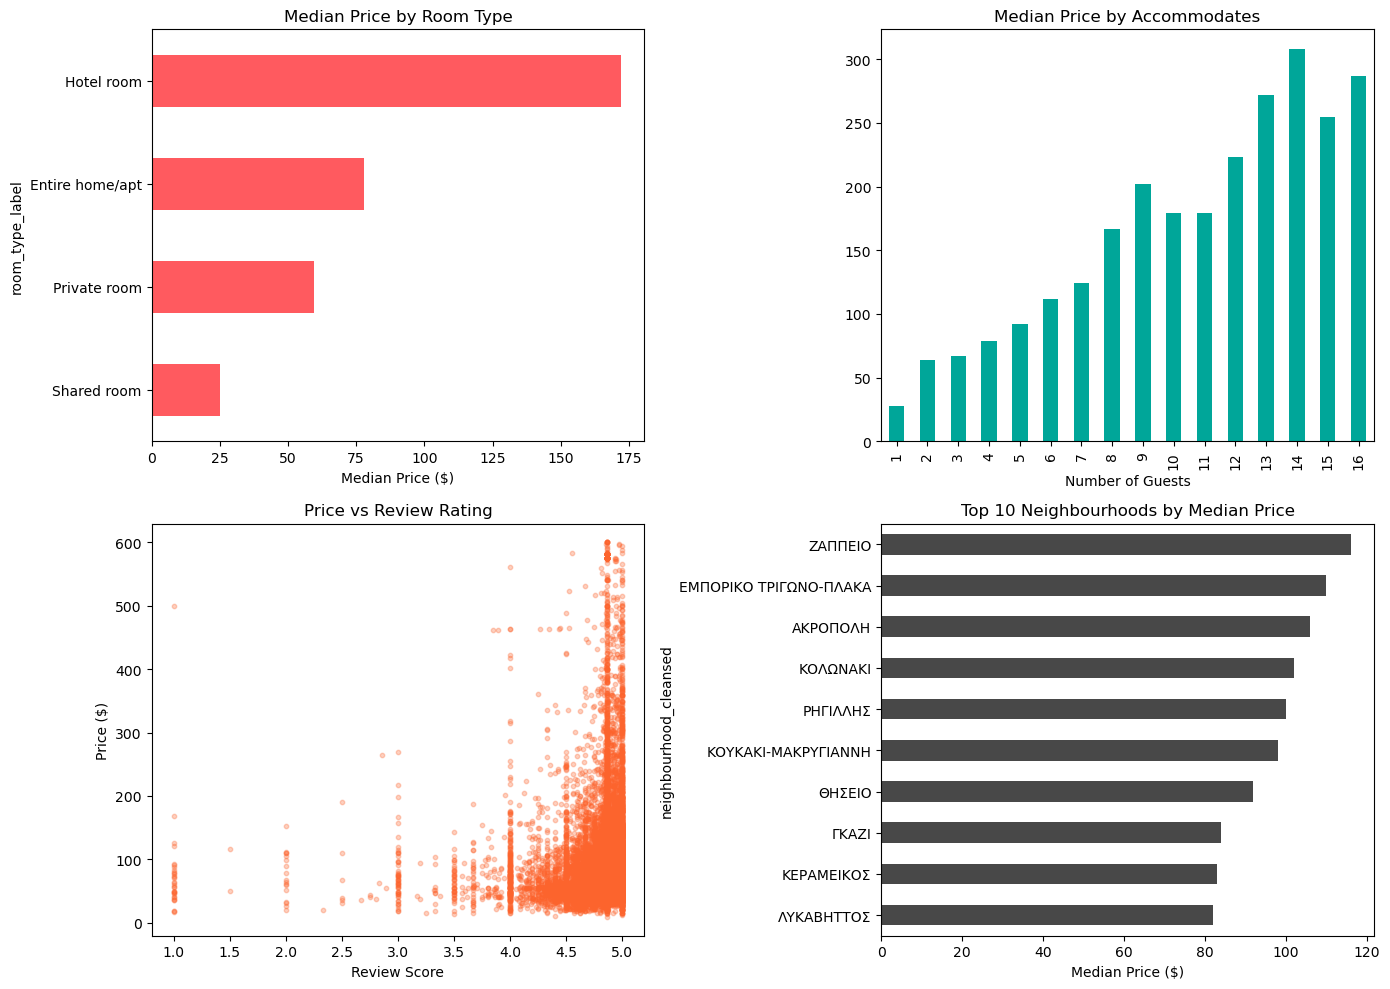

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df_eda = pd.read_csv('../data/processed/listings_featured.csv')

# Rebuild room_type_label from one-hot columns
room_cols = ['room_type_Entire home/apt', 'room_type_Hotel room', 
             'room_type_Private room', 'room_type_Shared room']
df_eda['room_type_label'] = df_eda[room_cols].idxmax(axis=1).str.replace('room_type_', '')

# Reload clean file for neighbourhood names
df_neigh = pd.read_csv('../data/processed/listings_clean.csv')
df_neigh['price'] = df_neigh['price'].replace('[\$,]', '', regex=True).astype(float)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Median price by room type
df_eda.groupby('room_type_label')['price'].median().sort_values().plot(
    kind='barh', ax=axes[0,0], color='#FF5A5F')
axes[0,0].set_title('Median Price by Room Type')
axes[0,0].set_xlabel('Median Price ($)')

# 2. Median price by accommodates
df_eda.groupby('accommodates')['price'].median().plot(
    kind='bar', ax=axes[0,1], color='#00A699')
axes[0,1].set_title('Median Price by Accommodates')
axes[0,1].set_xlabel('Number of Guests')

# 3. Price vs review rating
axes[1,0].scatter(df_eda['review_scores_rating'], df_eda['price'],
                  alpha=0.3, color='#FC642D', s=10)
axes[1,0].set_title('Price vs Review Rating')
axes[1,0].set_xlabel('Review Score')
axes[1,0].set_ylabel('Price ($)')

# 4. Top 10 neighbourhoods by median price
df_neigh.groupby('neighbourhood_cleansed')['price'].median().nlargest(10).sort_values().plot(
    kind='barh', ax=axes[1,1], color='#484848')
axes[1,1].set_title('Top 10 Neighbourhoods by Median Price')
axes[1,1].set_xlabel('Median Price ($)')

plt.tight_layout()
plt.savefig('../data/processed/images/eda_plots.png', dpi=150)
plt.show()

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import numpy as np 

df_model = pd.read_csv('../data/processed/listings_featured.csv')
#define feautured & target
X = df_model.drop(columns=['price', 'log_price']
                  if 'log_price' in df_model.columns else ['price'])
y = df_model['log_price'] if 'log_price' in df_model.columns else np.log1p(df_model['price'])

#Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2 , random_state=42)

print(f"Train size: {X_train.shape}")
print(f"Test size: {X_test.shape}")

#Linear regression
lr=LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

#Evaluate
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"\nLinear Regression:")
print(f"RMSE (log scale): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

# Convert back to dollar error
y_pred_dollars = np.expm1(y_pred)
y_test_dollars = np.expm1(y_test)
rmse_dollars = np.sqrt(mean_squared_error(y_test_dollars, y_pred_dollars))
print(f"RMSE (euros): €{rmse_dollars:.2f}")

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

y_pred_rf_euros = np.expm1(y_pred_rf)
rmse_rf_euros = np.sqrt(mean_squared_error(y_test_dollars, y_pred_rf_euros))

print(f"\nRandom Forest:")
print(f"RMSE (log scale): {rmse_rf:.4f}")
print(f"R² Score: {r2_rf:.4f}")
print(f"RMSE (euros): €{rmse_rf_euros:.2f}")

xgb = XGBRegressor(
    n_estimators = 300,
    learning_rate=0.05,
    max_depth = 6,
    random_state = 42,
)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

y_pred_xgb_euros = np.expm1(y_pred_xgb)
rmse_xgb_euros = np.sqrt(mean_squared_error(y_test_dollars, y_pred_xgb_euros))

print(f"\nXGBoost:")
print(f"RMSE (log scale): {rmse_xgb:.4f}")
print(f"R² Score: {r2_xgb:.4f}")
print(f"RMSE (euros): €{rmse_xgb_euros:.2f}")

Train size: (11502, 26)
Test size: (2876, 26)

Linear Regression:
RMSE (log scale): 0.4312
R² Score: 0.4911
RMSE (euros): €67.09

Random Forest:
RMSE (log scale): 0.3315
R² Score: 0.6991
RMSE (euros): €49.15

XGBoost:
RMSE (log scale): 0.3158
R² Score: 0.7271
RMSE (euros): €46.39


In [18]:
print(type(xgb))
print(dir(xgb))

<class 'xgboost.sklearn.XGBRegressor'>
['_Booster', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__sklearn_is_fitted__', '__sklearn_tags__', '__slotnames__', '__str__', '__subclasshook__', '__weakref__', '_can_use_inplace_predict', '_check_feature_names', '_check_n_features', '_configure_fit', '_create_dmatrix', '_doc_link_module', '_doc_link_template', '_estimator_type', '_get_iteration_range', '_get_param_names', '_get_tags', '_get_type', '_load_model_attributes', '_more_tags', '_repr_html_', '_repr_html_inner', '_repr_mimebundle_', '_set_evaluation_result', '_update_sklearn_tags_from_dict', '_validate_data', '_validate_params', '_wrapper_params', 'apply', 'base_score', 'best_iteration', 'best_score', '

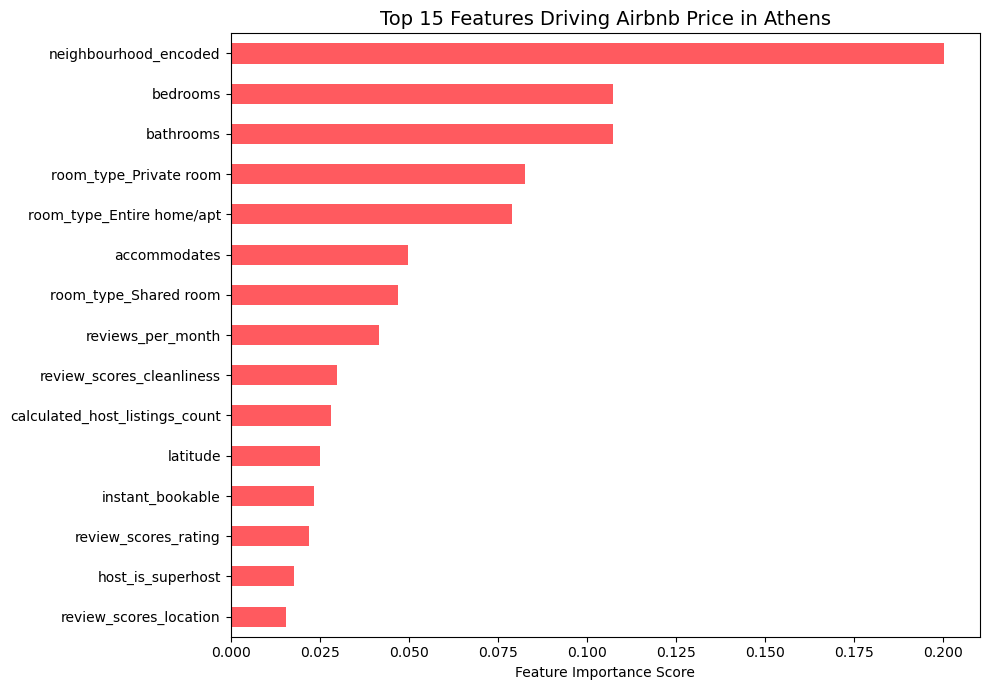

Top 5 price drivers:
neighbourhood_encoded        0.200376
bedrooms                     0.107365
bathrooms                    0.107314
room_type_Private room       0.082704
room_type_Entire home/apt    0.079012
dtype: float32


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importances
importance = pd.Series(xgb.feature_importances_, index=X_train.columns)
importance = importance.sort_values(ascending=True).tail(15)

fig, ax = plt.subplots(figsize=(10, 7))
importance.plot(kind='barh', ax=ax, color='#FF5A5F')
ax.set_title('Top 15 Features Driving Airbnb Price in Athens', fontsize=14)
ax.set_xlabel('Feature Importance Score')
plt.tight_layout()
plt.savefig('../data/processed/images/feature_importance.png', dpi=150)
plt.show()

# Print top 5
print("Top 5 price drivers:")
print(importance.tail(5).sort_values(ascending=False))

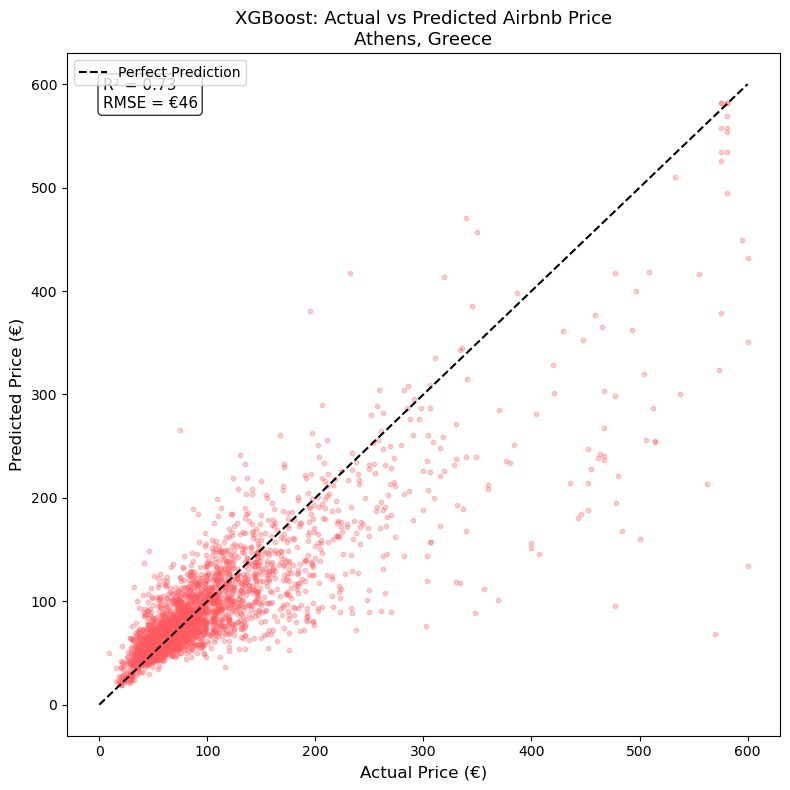

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

y_test_euros = np.expm1(y_test)
y_pred_euros = np.expm1(y_pred_xgb)

fig, ax = plt.subplots(figsize=(8,8))

ax.scatter(y_test_euros, y_pred_euros, alpha=0.3, color='#FF5A5F', s=10)

max_val = max(y_test_euros.max(), y_pred_euros.max())
ax.plot([0, max_val], [0, max_val], 'k--', linewidth=1.5, label='Perfect Prediction')

ax.set_xlabel('Actual Price (€)', fontsize=12)
ax.set_ylabel('Predicted Price (€)', fontsize=12)
ax.set_title('XGBoost: Actual vs Predicted Airbnb Price\nAthens, Greece', fontsize=13)
ax.legend()
ax.text(0.05, 0.92, f'R² = 0.73\nRMSE = €46',
        transform=ax.transAxes, fontsize=11,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig('../data/processed/images/actual_vs_predicted.png', dpi=150)
plt.show()